In [4]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import copy
import pandas as pd

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

mean, std = 0.2860, 0.3530
test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])
train_tf_plain = test_tf
train_tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(28, padding=2),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_plain = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=train_tf_plain)
train_aug   = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=train_tf_aug)
test_ds     = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=test_tf)
classes = test_ds.classes

PyTorch: 2.11.0+cu130 | urządzenie: cuda


In [5]:
g = torch.Generator().manual_seed(0)
targets = train_plain.targets
val_idx, tr_idx = [], []
for c in range(10):
    idx = (targets == c).nonzero(as_tuple=True)[0]
    idx = idx[torch.randperm(len(idx), generator=g)]
    val_idx += idx[:1000].tolist()
    tr_idx += idx[1000:].tolist()

train_ds_plain = Subset(train_plain, tr_idx)
train_ds_aug = Subset(train_aug, tr_idx)
val_ds = Subset(train_plain, val_idx)

# DataLoaders
batch_size = 128
train_plain_dl = DataLoader(train_ds_plain, batch_size=batch_size, shuffle=True)
train_aug_dl = DataLoader(train_ds_aug, batch_size=batch_size, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=256, shuffle=False)
train_eval_dl = DataLoader(train_ds_plain, batch_size=256, shuffle=False)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False)

print("Trening:", len(train_ds_plain), "| Walidacja:", len(val_ds), "| Test:", len(test_ds))

Trening: 50000 | Walidacja: 10000 | Test: 10000


In [6]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10,
                 use_bn=False, p_drop=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum/total, correct/total

def run_training_es(model, train_dl, val_dl, epochs=30, lr=1e-3, weight_decay=0.0,
                    optimizer="adam", use_scheduler=False, patience=3, verbose=True):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    if optimizer == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)

    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs//3), gamma=0.5) if use_scheduler else None

    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_loss, best_state, best_epoch, bad = float("inf"), None, 0, 0

    for epoch in range(1, epochs+1):
        model.train()
        run = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item()*yb.numel()

        if sched: sched.step()

        vl, va = evaluate(model, val_dl)
        hist["train_loss"].append(run/len(train_dl.dataset))
        hist["val_loss"].append(vl); hist["val_acc"].append(va)

        if verbose:
            print(f"Epoka {epoch:2d} | trening {hist['train_loss'][-1]:.3f} | val {vl:.3f} | acc {va*100:.2f}%")

        if vl < best_loss - 1e-4:
            best_loss, best_epoch, bad = vl, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                if verbose: print(f"Stop: brak poprawy od {patience} epok")
                break

    model.load_state_dict(best_state)
    if verbose: print(f"Przywrócono wagi z epoki {best_epoch} (val_loss {best_loss:.3f})")

    # Pomiar uczciwej luki generalizacji po treningu
    train_eval_loss, _ = evaluate(model, train_eval_dl)
    hist["gap"] = best_loss - train_eval_loss
    hist["best_epoch"] = best_epoch

    return hist

In [8]:
# Eksperymenty
EPOCHS = 15

results = []
models = {}

def run_experiment_variant(name, model, train_dl, **kwargs):
    print(f"\n Eksperyment: {name} ")
    torch.manual_seed(0)
    hist = run_training_es(model, train_dl, val_dl, epochs=EPOCHS, verbose=False, **kwargs)
    models[name] = model

    best_acc = max(hist["val_acc"])
    best_loss = min(hist["val_loss"])

    results.append({
        "Wariant": name,
        "Epoki": hist["best_epoch"],
        "Najlepsza val_acc": f"{best_acc*100:.2f}%",
        "Val_loss": f"{best_loss:.3f}",
        "Luka (val-train_eval)": f"{hist['gap']:.3f}"
    })
    return hist

baseline_model = MLP(use_bn=False, p_drop=0.0)
hist_base = run_experiment_variant("Baseline", baseline_model, train_plain_dl, optimizer="adam", lr=1e-3)

dropout_model = MLP(use_bn=False, p_drop=0.2)
hist_drop = run_experiment_variant("Dropout (p=0.2)", dropout_model, train_plain_dl, optimizer="adam", lr=1e-3)

wd_model = MLP(use_bn=False, p_drop=0.0)
hist_wd = run_experiment_variant("AdamW (wd=1e-2)", wd_model, train_plain_dl, optimizer="adamw", lr=1e-3, weight_decay=1e-2)

aug_model = MLP(use_bn=False, p_drop=0.0)
hist_aug = run_experiment_variant("Augmentacja", aug_model, train_aug_dl, optimizer="adam", lr=1e-3)

results_df = pd.DataFrame(results)
print("\n Podsumowanie eksperymentów na zbiorze walidacyjnym: ")
print(results_df.to_string(index=False))

best_variant_idx = results_df['Najlepsza val_acc'].str.rstrip('%').astype(float).idxmax()
best_variant_name = results_df.iloc[best_variant_idx]['Wariant']
best_hist = hist_base if best_variant_name == "Baseline" else (
    hist_drop if best_variant_name == "Dropout (p=0.2)" else (
    hist_wd if best_variant_name == "AdamW (wd=1e-2)" else hist_aug
    )
)
best_model = models[best_variant_name]

print(f"\nNajlepszy model na walidacji: {best_variant_name}")

# Ocena końcowa najlepszego modelu na zbiorze testowym
test_loss, test_acc = evaluate(best_model, test_dl)
print(f"Wynik na zbiorze testowym (dla {best_variant_name}) ---")
print(f"Test Accuracy: {test_acc*100:.2f}% | Test Loss: {test_loss:.3f}")


 Eksperyment: Baseline 

 Eksperyment: Dropout (p=0.2) 

 Eksperyment: AdamW (wd=1e-2) 

 Eksperyment: Augmentacja 

 Podsumowanie eksperymentów na zbiorze walidacyjnym: 
        Wariant  Epoki Najlepsza val_acc Val_loss Luka (val-train_eval)
       Baseline      6            89.31%    0.302                 0.073
Dropout (p=0.2)      7            88.82%    0.304                 0.062
AdamW (wd=1e-2)     10            89.65%    0.301                 0.114
    Augmentacja     14            87.73%    0.340                 0.023

Najlepszy model na walidacji: AdamW (wd=1e-2)
Wynik na zbiorze testowym (dla AdamW (wd=1e-2)) ---
Test Accuracy: 88.11% | Test Loss: 0.350


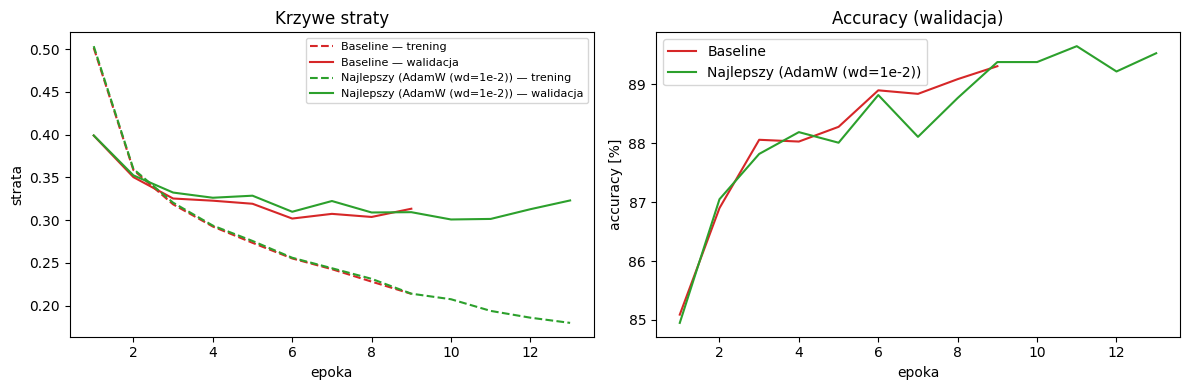

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for name, h, c in [("Baseline", hist_base, "tab:red"), (f"Najlepszy ({best_variant_name})", best_hist, "tab:green")]:
    epochs_range = range(1, len(h["train_loss"]) + 1)
    ax1.plot(epochs_range, h["train_loss"], "--", color=c, label=f"{name} — trening")
    ax1.plot(epochs_range, h["val_loss"],  "-",  color=c, label=f"{name} — walidacja")
    ax2.plot(epochs_range, [a*100 for a in h["val_acc"]], color=c, label=name)

ax1.set_xlabel("epoka"); ax1.set_ylabel("strata"); ax1.legend(fontsize=8); ax1.set_title("Krzywe straty")
ax2.set_xlabel("epoka"); ax2.set_ylabel("accuracy [%]"); ax2.legend(); ax2.set_title("Accuracy (walidacja)")
plt.tight_layout(); plt.show()

In [13]:
print("\nPorównanie przerwy train-test:")
base_gap = hist_base['gap']
best_gap = best_hist['gap']
print(f"Baseline: {base_gap:.3f}")
print(f"Najlepszy wariant: ({best_variant_name}): {best_gap:.3f}")
if best_gap < base_gap:
    print("Komentarz: Zastosowana regularyzacja skutecznie zmniejszyła przeuczenie (luka generalizacji jest mniejsza).")
else:
    print("Komentarz: Mimo zastosowania regularyzacji, luka generalizacji nie zmniejszyła się znacząco lub wzrosła.")


Porównanie przerwy train-test:
Baseline: 0.073
Najlepszy wariant: (AdamW (wd=1e-2)): 0.114
Komentarz: Mimo zastosowania regularyzacji, luka generalizacji nie zmniejszyła się znacząco lub wzrosła.



Zakres Dodatkowy: Przegląd współczynnika uczenia (LR) na 4 epokach:
lr=0.1     -> val_acc 10.27%
lr=0.01    -> val_acc 87.01%
lr=0.001   -> val_acc 88.36%
lr=0.0001  -> val_acc 85.91%


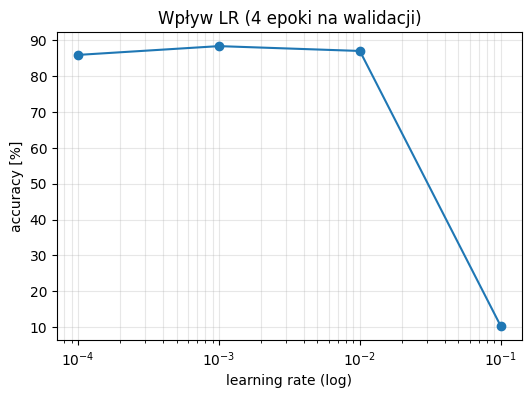

In [14]:
print("\nZakres Dodatkowy: Przegląd współczynnika uczenia (LR) na 4 epokach:")
lrs = [1e-1, 1e-2, 1e-3, 1e-4]
acc_by_lr = []

for lr in lrs:
    torch.manual_seed(0)
    m = MLP(use_bn=False, p_drop=0.0)
    h = run_training_es(m, train_plain_dl, val_dl, epochs=4, lr=lr, patience=4, verbose=False)
    acc_by_lr.append(max(h["val_acc"]))
    print(f"lr={lr:<7} -> val_acc {max(h['val_acc'])*100:.2f}%")

plt.figure(figsize=(6,4))
plt.semilogx(lrs, [a*100 for a in acc_by_lr], "o-")
plt.xlabel("learning rate (log)"); plt.ylabel("accuracy [%]"); plt.title("Wpływ LR (4 epoki na walidacji)")
plt.grid(True, which="both", alpha=0.3); plt.show()